# 02 · 数据清洗、频率转换与单位

**学习目标**

1. 分清 **指数水平 (index level)**、**环比 (q/q)**、**同比 (y/y)**、**对数差分 (log difference)**、
   **百分比变化 (percent change)** 和 **百分点变化 (percentage-point change)**。
2. 理解把日度数据聚合为季度时的选择：均值 vs 期末值、覆盖率要求、"比值的均值" vs "均值的比值"。
3. 用 `validate_series` 和 `seasonality_test` 做数据质量检查。
4. 构建并读取标准化数据集 `macro_{daily,monthly,quarterly}.parquet`。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from economic_lab.data import transforms as tf
from economic_lab.data.build import load_dataset
from economic_lab.data.validation import missing_report, seasonality_test, validate_series
from economic_lab.visualization import SERIES, use_lab_style

use_lab_style()
q = load_dataset("quarterly")
m = load_dataset("monthly")
d = load_dataset("daily")
DATA_KIND = q.attrs["data_kind"]
print("DATA KIND:", DATA_KIND.upper())
for note in q.attrs.get("notes", []):
    print(" -", note)

DATA KIND: REAL
 - brent_usd monthly/quarterly from EIA monthly averages (daily series sparse in 1993-2005); oil_nzd = monthly brent_usd / monthly mean nzd_usd, quarterly = mean of 3 months.
 - IGREA dates normalised to month start; quarterly = mean of 3 months.
 - RBNZ hm1.xlsx: cpi, cpi_tradable, cpi_nontradable, cpi_petrol, cpi_ex_petrol, ppi_inputs, core_sfm_yy (1988-01 to 2026-04).
 - RBNZ hm5.xlsx: gdp_real, gdp_nominal, consumption_real, inv_resid_real, inv_other_real, exports_real, imports_real (1987-04 to 2026-04).
 - RBNZ hm9.xlsx: unemployment, lci (1994-01 to 2026-04).
 - RBNZ hm14.xlsx: infl_exp_1y, infl_exp_2y (1987-07 to 2026-07).
 - RBNZ hb1-daily.xlsx: twi (2018-01 to 2026-10).
 - RBNZ hb2-daily-close.xlsx: ocr, bank_bill_90d, govt_bond_10y (2018-01 to 2026-10).
 - RBNZ daily series (B1/B2) averaged over business days to months/quarters (>= 80% coverage); OCR and yields are period averages, not end-of-period.
 - Headline CPI from RBNZ M1. Cross-check vs OECD/FRED CPI q

> **如果上面显示 `SYNTHETIC`**：说明 `data/processed/` 中没有真实数据集（例如在 CI 中），本 notebook
> 使用已知参数的合成数据。所有数字只用于演示方法，**不是新西兰的经验结论**。
> 生成真实数据集：`uv run python scripts/data_download.py && uv run python scripts/build_datasets.py`。

## 1. 单位：六个容易混淆的概念

设 $P_t$ 为季度 CPI 指数水平（例如 2015 = 100）。

| 概念 | 公式 | 单位 | 例子 |
|---|---|---|---|
| 指数水平 | $P_t$ | 指数点 | 132.8 |
| 环比通胀 (q/q) | $\pi^{qq}_t = 100\,(P_t/P_{t-1}-1)$ | % (每季度) | 0.9 |
| 年化环比 | $100\,[(1+\pi^{qq}_t/100)^4-1]$ | % 年率 | 3.6 |
| 同比通胀 (y/y) | $\pi^{yy}_t = 100\,(P_t/P_{t-4}-1)$ | % | 2.5 |
| 对数差分 | $100\,(\ln P_t-\ln P_{t-1})$ | 对数点 ≈ % | 0.896 |
| 百分点变化 | $\pi_t-\pi_{t-1}$ | 百分点 (pp) | +0.3 pp |

关键关系：

* $\ln(1+g) \approx g$ 仅在 $g$ 较小时成立。油价一个季度上涨 40% 时，对数差分只有 $100\ln 1.4 = 33.6$ 对数点 —— 差别很大。
* 对数差分可以相加：$\ln P_t - \ln P_{t-4} = \sum_{j=0}^{3}\Delta\ln P_{t-j}$；百分比变化不能直接相加。
* 利率从 2% 升到 3% 是 **+1 个百分点**，也是 **+50%**。说 "利率上升 1%" 是有歧义的。
* 同比通胀约等于最近四个环比的和，因此它是一个 **移动平均**，比环比更平滑、但滞后约 1.5 个季度。

In [2]:
cpi = q["cpi"].dropna()
infl = pd.DataFrame({
    "qoq_pct": tf.pct_change(cpi, 1, freq="Q"),
    "qoq_log": tf.log_diff(cpi, 1, freq="Q"),
    "qoq_annualised": tf.annualise(tf.pct_change(cpi, 1, freq="Q"), 4),
    "yoy_pct": tf.yoy(cpi, "Q"),
})
infl["yoy_minus_sum4_qoq_log"] = infl["yoy_pct"] - infl["qoq_log"].rolling(4).sum()
infl.dropna().tail(6).round(3)

,qoq_pct,qoq_log,qoq_annualised,yoy_pct,yoy_minus_sum4_qoq_log
date,,,,,
2025-01-01,0.932,0.928,3.782,2.526,0.031
2025-04-01,0.539,0.537,2.173,2.673,0.035
2025-07-01,0.995,0.990,4.041,3.047,0.045
2025-10-01,0.607,0.605,2.448,3.108,0.047
2026-01-01,0.904,0.900,3.667,3.079,0.046
2026-04-01,1.494,1.483,6.110,4.058,0.080


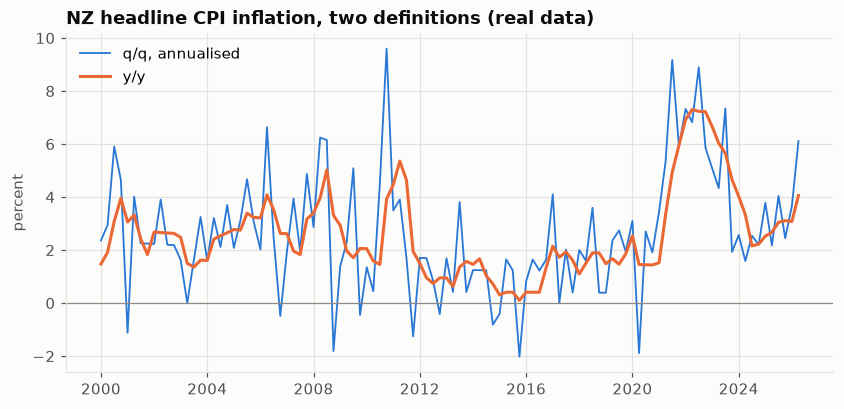

In [3]:
recent = infl.loc["2000":]
fig, ax = plt.subplots()
ax.plot(recent.index, recent["qoq_annualised"], color=SERIES[0], linewidth=1.2, label="q/q, annualised")
ax.plot(recent.index, recent["yoy_pct"], color=SERIES[1], label="y/y")
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_title(f"NZ headline CPI inflation, two definitions ({DATA_KIND} data)")
ax.set_ylabel("percent")
ax.legend(loc="upper left")
plt.show()

年化环比波动远大于同比：同比是四个季度的累积，相当于平滑了噪声。
建模时 **必须先决定目标变量是哪一个**，并在所有模型中保持一致。本项目在季度模型中默认使用 q/q 百分比变化。

## 2. 汇率换算：$\text{oil}^{NZD}_d = \text{oil}^{USD}_d / \text{NZDUSD}_d$

`NZDUSD` 报价 = 1 新西兰元可以换多少美元（例如 0.60）。那么 1 美元 = 1/0.60 新西兰元，因此：

$$\text{oil}^{NZD} = \text{oil}^{USD} \times \frac{1}{\text{NZDUSD}} = \frac{\text{oil}^{USD}}{\text{NZDUSD}}.$$

取对数：$\ln \text{oil}^{NZD} = \ln\text{oil}^{USD} - \ln\text{NZDUSD}$。所以 **新西兰元贬值（NZDUSD 下降）会提高以新西兰元计的油价**，
即使国际油价不变。这一点在 Track B 中区分 "油价冲击" 与 "汇率冲击" 时很重要。

In [4]:
check = pd.DataFrame({
    "dlog_oil_nzd": tf.log_diff(q["oil_nzd"].dropna(), 1),
    "dlog_oil_usd": tf.log_diff(q["brent_usd"].dropna(), 1),
    "dlog_nzdusd": tf.log_diff(q["nzd_usd"].dropna(), 1),
}).dropna()
check["identity_gap"] = check["dlog_oil_nzd"] - (check["dlog_oil_usd"] - check["dlog_nzdusd"])
print("max |identity gap| (log points):", check["identity_gap"].abs().max().round(4))
print("corr(dlog oil_usd, dlog nzdusd):", check[["dlog_oil_usd", "dlog_nzdusd"]].corr().iloc[0, 1].round(3))

max |identity gap| (log points): 0.7856
corr(dlog oil_usd, dlog nzdusd): 0.396


如果季度 `oil_nzd` 恰好等于季度 `brent_usd / nzd_usd`，恒等式误差为零。在真实数据中误差接近零但不完全为零
（见下一节：比值是在月度层面计算再平均的）。

油价与 NZD/USD 的变化是 **正相关** 的：新西兰元被视为 "商品货币"，全球需求强劲时油价和 NZD 同时上涨，
NZD 升值部分抵消了以 NZD 计的油价上涨。这本身就是一个识别问题的伏笔：观察到的油价变动不是外生的。

## 3. 日度 → 季度：均值、期末值与覆盖率

* **均值**：CPI 是在整个季度内采集的价格，所以影响季度 CPI 的是季度内的 *平均* 油价，而不是季末那一天的油价。
* **期末值 (end of period)**：适合存量或预期变量（例如季末的利率曲线）。
* **覆盖率**：`aggregate` 要求一个季度至少有 80% 的工作日有观测，否则返回缺失，而不是把几天的平均当成整个季度的平均。

**比值的均值 ≠ 均值的比值。** 由于 EIA 日度数据在 1990 年代稀疏，季度 `oil_nzd` 用月度平均构造：
$\overline{\text{oil}^{USD}}_m / \overline{\text{NZDUSD}}_m$。而 "理想" 构造是 $\overline{\text{oil}^{USD}_d/\text{NZDUSD}_d}$。
两者之差来自季度内油价与汇率的协方差（Jensen 不等式），在两者都可用的样本中可以直接比较：

In [5]:
if "oil_nzd_from_daily" in q.columns:
    both = q[["oil_nzd", "oil_nzd_from_daily"]].dropna()
    gap = 100 * np.log(both["oil_nzd"] / both["oil_nzd_from_daily"])
    print(f"{len(both)} quarters with both constructions")
    print(gap.describe().round(3))
else:
    print("Synthetic data: only the daily-based construction exists.")

116 quarters with both constructions
count    116.000
mean      -0.024
std        0.355
min       -1.684
25%       -0.123
50%        0.020
75%        0.129
max        1.196
dtype: float64


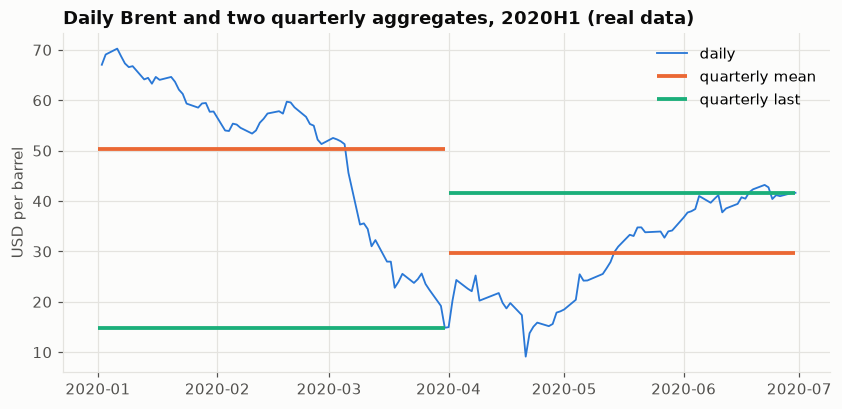

In [6]:
sample = d["brent_usd"].dropna().loc["2020-01":"2020-06"]
fig, ax = plt.subplots()
ax.plot(sample.index, sample, color=SERIES[0], linewidth=1.2, label="daily")
for how, color in [("mean", SERIES[1]), ("last", SERIES[2])]:
    agg = tf.aggregate(sample, "Q", how)
    for start, val in agg.items():
        end = start + pd.offsets.QuarterEnd(0)
        ax.hlines(val, start, end, color=color, linewidth=2.5, label=f"quarterly {how}" if start == agg.index[0] else None)
ax.set_title(f"Daily Brent and two quarterly aggregates, 2020H1 ({DATA_KIND} data)")
ax.set_ylabel("USD per barrel")
ax.legend()
plt.show()

（真实数据中）2020 年第二季度油价暴跌后回升：季末值和季度均值相差很大。用哪一个，取决于你认为什么样的价格进入了 CPI。

## 4. 数据质量检查

`validate_series` 检查：索引类型、重复日期、排序、数值类型、频率（间隔与是否对齐到季初/月初）、取值范围、样本内缺失、
起始日期。日度数据还检查每年的工作日覆盖率。

In [7]:
reports = [
    validate_series(q["cpi"].dropna(), expected_freq="Q", min_value=0.01),
    validate_series(q["oil_nzd"].dropna(), expected_freq="Q", min_value=0.0),
    validate_series(d["brent_usd"].dropna(), expected_freq="B", min_value=0.0, max_value=500),
    validate_series(m["nzd_usd"].dropna(), expected_freq="M", min_value=0.2, max_value=1.6),
]
for r in reports:
    print(r)

bad = pd.Series([100.0, 0.0, 101.0], index=pd.to_datetime(["2020-01-01", "2020-04-15", "2020-04-15"]))
print(validate_series(bad, expected_freq="Q", min_value=0.01, name="deliberately broken"))

[PASS] cpi: 154 obs, 1988-01-01 to 2026-04-01
[PASS] oil_nzd: 157 obs, 1987-07-01 to 2026-07-01
[PASS] brent_usd: 9102 obs, 1987-05-20 to 2026-10-06
  WARNING 22 gaps longer than one week (max 13 days)
  WARNING 9 years with <80% business-day coverage (1994-2002, min 49%)
[FAIL] nzd_usd: 667 obs, 1971-01-01 to 2026-09-01
  ERROR   2 irregular spacings for M data (expected 28-31 days)
[FAIL] deliberately broken: 3 obs, 2020-01-01 to 2020-04-15
  ERROR   1 duplicate dates
  ERROR   2 irregular spacings for Q data (expected 90-92 days)
  ERROR   dates not aligned to Q period start
  ERROR   1 values below 0.01


上面的输出中，月度 `nzd_usd` 在真实数据下 **未通过** 校验：1971 年有两个月缺失（日度数据在 1971 年 8 月和 12 月各有一个超过一周的缺口，
覆盖率低于 80%，`aggregate` 拒绝计算这两个月的均值）。1971 年 8 月正是 "尼克松冲击"（美元停止兑换黄金、外汇市场关闭）。
校验报告的作用正是让这种问题显式暴露出来；季度建模样本从 1987 年开始，不受影响。合成数据下这一检查会通过。

In [8]:
missing_report(q.loc["1990":])

,n_missing,share_missing,first_valid,last_valid
brent_usd,0,0.0,1990-01-01 00:00:00,2026-07-01 00:00:00
nzd_usd,0,0.0,1990-01-01 00:00:00,2026-07-01 00:00:00
oil_nzd,0,0.0,1990-01-01 00:00:00,2026-07-01 00:00:00
oil_nzd_from_daily,41,0.278912,1990-01-01 00:00:00,2026-07-01 00:00:00
igrea,1,0.006803,1990-01-01 00:00:00,2026-04-01 00:00:00
twi,112,0.761905,2018-01-01 00:00:00,2026-07-01 00:00:00
ocr,112,0.761905,2018-01-01 00:00:00,2026-07-01 00:00:00
bank_bill_90d,112,0.761905,2018-01-01 00:00:00,2026-07-01 00:00:00
govt_bond_10y,112,0.761905,2018-01-01 00:00:00,2026-07-01 00:00:00
cpi,1,0.006803,1990-01-01 00:00:00,2026-04-01 00:00:00


### 季节性检查

Stats NZ 的 CPI **没有季节调整**。检验方法：把环比通胀对常数和 3 个季度虚拟变量回归，

$$\pi_t = \alpha + \sum_{s=2}^{4}\delta_s D_{s,t} + u_t,$$

用 F 检验 $H_0:\delta_2=\delta_3=\delta_4=0$。如果一个声称 "已季调" 的序列拒绝 $H_0$，就是一个危险信号；
对未季调的 CPI，拒绝 $H_0$ 则提示建模时应考虑季度虚拟变量。

In [9]:
pi = tf.pct_change(q["cpi"].dropna(), 1, freq="Q").loc["1992":]
res = seasonality_test(pi, "Q")
print({k: round(v, 4) for k, v in res.items()})
print(pi.groupby(pi.index.quarter).mean().round(3).rename("mean q/q inflation by quarter"))

{'F': 2.7638, 'df1': 3, 'df2': 134, 'p_value': 0.0445}
date
1    0.495
2    0.638
3    0.788
4    0.453
Name: mean q/q inflation by quarter, dtype: float64


## 5. 标准化数据集

| 文件 | 频率 | 用途 |
|---|---|---|
| `macro_daily.parquet` | 工作日 | 混频模型、事件研究 |
| `macro_monthly.parquet` | 月度（月初日期） | 商品价格、IGREA |
| `macro_quarterly.parquet` | 季度（季初日期） | **主建模数据集** |

每个文件旁边有一个 `.meta.json`：构建时间、`data_kind`（real/synthetic）、清洗说明、原始文件的 SHA-256。
**Parquet 中只存水平值**（指数、价格），通胀率等变化率在模型代码中用 `transforms` 计算，以避免单位混淆。

## 练习

1. **Easy** — 把季度聚合方式从均值改为期末值，重新计算 `dlog_oil_nzd`，比较两者的标准差。
2. **Intermediate** — 写函数 `annualised_from_log(dlog, m)`，把对数差分转换为年化百分比，并验证它等于 `annualise(pct_change(...), m)`。
3. **Advanced** — 只用 2000 年以后的数据，计算 `oil_nzd` 两种构造（月度比值 vs 日度比值的均值）的季度对数变化之差，
   检验这个差异与 NZD/USD 季度内波动率的关系。为什么理论上应该相关？

## 参考答案

In [10]:
# Exercise 1
daily_oil_nzd = d["oil_nzd"].dropna()
eop = tf.log_diff(tf.aggregate(daily_oil_nzd, "Q", "last"), 1)
avg = tf.log_diff(tf.aggregate(daily_oil_nzd, "Q", "mean"), 1)
print("std of quarterly dlog oil_nzd: end-of-period %.2f vs mean %.2f" % (eop.std(), avg.std()))
# Averaging removes within-quarter noise, so the average-based change is smoother.

# Exercise 2
def annualised_from_log(dlog: pd.Series, m: int) -> pd.Series:
    return 100 * (np.exp(m * dlog / 100) - 1)

a = annualised_from_log(tf.log_diff(cpi, 1), 4)
b = tf.annualise(tf.pct_change(cpi, 1), 4)
print("max abs difference:", float((a - b).abs().max()))

std of quarterly dlog oil_nzd: end-of-period 28.95 vs mean 17.42
max abs difference: 4.2099657093785936e-13


In [11]:
# Exercise 3
if "oil_nzd_from_daily" in q.columns:
    z = q[["oil_nzd", "oil_nzd_from_daily"]].loc["2000":].dropna()
    diff = tf.log_diff(z["oil_nzd"], 1) - tf.log_diff(z["oil_nzd_from_daily"], 1)
    fx_vol = np.log(d["nzd_usd"].dropna()).diff().groupby(pd.Grouper(freq="QS")).std() * 100
    joined = pd.concat([diff.abs().rename("abs_diff"), fx_vol.rename("fx_vol")], axis=1).dropna()
    print(joined.corr().round(3))
    # The gap comes from the within-period covariance of oil and 1/FX (Jensen's inequality),
    # which is larger when the exchange rate moves more within the month.
else:
    print("Requires real data.")

          abs_diff  fx_vol
abs_diff     1.000  -0.004
fx_vol      -0.004   1.000


/var/folders/x5/811605315pz3sbnmkwzjmcw00000gn/T/ipykernel_73684/1651054403.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  joined = pd.concat([diff.abs().rename("abs_diff"), fx_vol.rename("fx_vol")], axis=1).dropna()
